# Modelo predictivo — EAC 2024
### Etapa 3, tarea 3 · Proyecto DataXperience · Universidad EAN

Cuaderno complementario de `EAC_2024_analisis.ipynb`. Parte del dataset ya depurado en el
Módulo 1 y de los hallazgos estadísticos del Módulo 2.

**Pregunta:** ¿se puede estimar el tamaño económico de una empresa comercial a partir de datos
que se observan desde fuera, sin acceso a sus estados financieros?

## 1.1 Librerías y rutas


In [1]:
# 1.1 — Librerías, rutas y semilla
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

SEMILLA = 42          # reproducibilidad: sin esto las métricas cambian en cada ejecución

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
print("Listo —", (PROCESADOS / "eac_2024_limpio.csv").exists())



Listo — True


### 1.2 Cargar el dataset depurado

Se parte del CSV que produce el Módulo 1, no del microdato crudo: la limpieza, el tratamiento de
nulos y las variables derivadas ya están hechos allí.


In [2]:
# 1.2 — Cargar el dataset depurado
df = pd.read_csv(PROCESADOS / "eac_2024_limpio.csv")
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")
df[["personal_total", "remuneracion_total", "produccion_bruta"]].describe().round(1)


9,909 filas x 71 columnas


,personal_total,remuneracion_total,produccion_bruta
count,"9,909.000","9,909.000","9,909.000"
mean,75.400,"3,340,331.200","12,249,807.400"
std,405.000,"16,521,944.800","59,901,198.300"
min,1.000,0.000,"-7,456,228.000"
25%,13.000,"402,242.800","1,188,863.000"
50%,25.000,"866,638.300","2,802,717.000"
75%,53.000,"2,164,803.100","7,290,947.000"
max,"13,938.000","549,326,039.300","2,007,621,605.000"


### 1.3 La trampa: por qué no se puede usar cualquier predictor

Antes de elegir variables hay que mirar las identidades contables de la EAC. La producción bruta
no es independiente del consumo intermedio ni del valor agregado: **es su suma**, exactamente, en
todas las filas.

Un modelo que prediga la producción bruta a partir de sus propios componentes obtiene un R² de
1,000 y un error de cero. No ha aprendido nada: ha despejado una resta. Es el error más
peligroso de este tipo de datos, porque el resultado no parece malo, parece perfecto.

> **Resultado:** las dos primeras identidades se cumplen en el 100 % de las filas. La tercera
> (producción bruta = ventas − costo de la mercancía) solo en el 50,3 %, así que no es una
> identidad sino una aproximación. Y la demostración: R² = 1,0000 con coeficientes exactamente
> 1,0 y 1,0.


In [3]:
# 1.3 — Identidades contables: qué variables NO pueden ser predictores
OBJETIVO = "produccion_bruta"

identidades = pd.DataFrame({
    "identidad": [
        "produccion_bruta = valor_agregado + consumo_intermedio",
        "valor_agregado   = produccion_bruta - consumo_intermedio",
        "produccion_bruta = ventas - costo_mercancia_vendida",
    ],
    "desviacion": [
        (df["produccion_bruta"] - (df["valor_agregado"] + df["consumo_intermedio"])).abs(),
        (df["valor_agregado"] - (df["produccion_bruta"] - df["consumo_intermedio"])).abs(),
        (df["produccion_bruta"] - (df["ventas"] - df["costo_mercancia_vendida"])).abs(),
    ],
})
identidades["% filas que la cumplen"] = [(d < 1).mean() * 100 for d in identidades["desviacion"]]
display(identidades[["identidad", "% filas que la cumplen"]].round(2))

# Demostración de la trampa: predecir con los propios componentes
_X = df[["consumo_intermedio", "valor_agregado"]]
_modelo_trampa = LinearRegression().fit(_X, df[OBJETIVO])
print(f"R² usando los dos componentes: {r2_score(df[OBJETIVO], _modelo_trampa.predict(_X)):.4f}")
print(f"Coeficientes aprendidos:       {_modelo_trampa.coef_.round(3)}  <- exactamente 1 y 1")


,identidad,% filas que la cumplen
0,produccion_bruta = valor_agregado + consumo_in...,100.000
1,valor_agregado = produccion_bruta - consumo_...,100.000
2,produccion_bruta = ventas - costo_mercancia_ve...,50.290


R² usando los dos componentes: 1.0000
Coeficientes aprendidos:       [1. 1.]  <- exactamente 1 y 1


## 2. El conjunto de modelado

### 2.1 Variables del modelo

**Objetivo:** la producción bruta de la empresa.

**Predictores:** el personal ocupado y la remuneración total. Se eligen por dos razones. La
primera es la regla de 1.3: ninguno es componente contable del objetivo. La segunda es lo que
hace útil al modelo: **son datos observables desde fuera de la empresa**. Una entidad financiera
o un gremio conoce la nómina y la plantilla sin tener acceso a los estados financieros.

El logaritmo no existe para cero, así que se excluyen las empresas con algún valor no positivo
—principalmente las 88 sin personal remunerado—. Es una limitación del modelo y queda declarada.

> **Resultado:** 9.791 empresas utilizables, 118 excluidas (1,2 % del total).


In [4]:
# 2.1 — Variables del modelo y filtro de valores no positivos
PREDICTORES = ["personal_total", "remuneracion_total"]
COLS = PREDICTORES + [OBJETIVO]

antes = len(df)
modelo_df = df[COLS].dropna()
modelo_df = modelo_df[(modelo_df > 0).all(axis=1)]
excluidas = antes - len(modelo_df)

print(f"Empresas utilizables: {len(modelo_df):,}")
print(f"Excluidas por valores <= 0: {excluidas} ({excluidas / antes * 100:.1f} %)")
modelo_df.describe().round(1)


Empresas utilizables: 9,791
Excluidas por valores <= 0: 118 (1.2 %)


,personal_total,remuneracion_total,produccion_bruta
count,"9,791.000","9,791.000","9,791.000"
mean,76.100,"3,376,035.000","12,376,366.900"
std,407.400,"16,616,924.300","60,247,185.800"
min,1.000,1.000,"7,921.000"
25%,13.000,"410,839.000","1,212,067.500"
50%,25.000,"884,349.900","2,839,371.000"
75%,54.000,"2,189,950.000","7,358,073.500"
max,"13,938.000","549,326,039.300","2,007,621,605.000"


### 2.2 Partición entrenamiento / prueba

El 80 % de las empresas se usa para ajustar el modelo y el 20 % restante se reserva: el modelo
no las ve durante el entrenamiento. Todas las métricas que se reporten salen de ese 20 %.

Evaluar con los mismos datos del entrenamiento mide cuánto memorizó el modelo, no cuánto sabe
predecir. En 4.2 se cuantifica la diferencia.

> **Resultado:** 7.832 empresas de entrenamiento y 1.959 de prueba.


In [5]:
# 2.2 — Partición entrenamiento / prueba
X = modelo_df[PREDICTORES]
y = modelo_df[OBJETIVO]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_tr):,} empresas")
print(f"Prueba:        {len(X_te):,} empresas  (el modelo nunca las ve al entrenar)")


Entrenamiento: 7,832 empresas
Prueba:        1,959 empresas  (el modelo nunca las ve al entrenar)


## 3. Entrenamiento

### 3.1 Regresión lineal simple (log–log)

El modelo más sencillo posible: la producción bruta a partir del personal ocupado.

Se ajusta sobre los logaritmos de ambas variables, no sobre sus valores. El Módulo 2 ya midió por
qué: con asimetría de +19 y Gini de 0,79, una recta en escala original queda determinada por un
puñado de empresas gigantes y describe mal a las 9.000 restantes.

En un modelo log–log el coeficiente es una **elasticidad**: dice en qué porcentaje cambia la
producción cuando el personal cambia un 1 %.

> **Resultado:** elasticidad de 1,005 — la producción crece casi exactamente en proporción al
> personal. Duplicar la plantilla se asocia a multiplicar la producción por 2,01.


In [6]:
# 3.1 — Regresión lineal simple en escala logarítmica
simple = LinearRegression().fit(np.log(X_tr[["personal_total"]]), np.log(y_tr))
pred_simple = np.exp(simple.predict(np.log(X_te[["personal_total"]])))

b = simple.coef_[0]
print(f"log(produccion_bruta) = {simple.intercept_:.3f} + {b:.3f} * log(personal_total)")
print(f"Elasticidad: un 1 % más de personal -> un {b:.2f} % más de producción bruta")
print(f"Duplicar el personal multiplica la producción por {2 ** b:.2f}")


log(produccion_bruta) = 11.606 + 1.005 * log(personal_total)
Elasticidad: un 1 % más de personal -> un 1.01 % más de producción bruta
Duplicar el personal multiplica la producción por 2.01


### 3.2 Regresión lineal múltiple (log–log)

Se añade la remuneración total como segundo predictor.

El reparto de los coeficientes es el resultado interesante: la elasticidad del personal cae a
0,16 mientras la de la remuneración es 0,81. **Cuánto paga una empresa dice bastante más sobre su
tamaño que a cuánta gente emplea.** Encaja con lo que el Módulo 2 encontró en 2.5.2: como la
remuneración por trabajador crece con el tamaño, la nómina ya contiene información de escala que
el simple conteo de empleados no tiene.

> **Resultado:** elasticidades de 0,157 para el personal y 0,807 para la remuneración.


In [7]:
# 3.2 — Regresión lineal múltiple en escala logarítmica
multiple = LinearRegression().fit(np.log(X_tr), np.log(y_tr))
pred_multiple = np.exp(multiple.predict(np.log(X_te)))

print("Elasticidades estimadas:")
for nombre, coef in zip(PREDICTORES, multiple.coef_):
    print(f"  {nombre:20s} {coef:+.3f}")
print(f"  {'(intercepto)':20s} {multiple.intercept_:+.3f}")


Elasticidades estimadas:
  personal_total       +0.157
  remuneracion_total   +0.807
  (intercepto)         +3.293


### 3.3 El mismo modelo sin logaritmos

No es un modelo candidato: es el contraste. Sin él, decir "uso escala logarítmica por la
asimetría" sería una afirmación sin evidencia. Con él, la evidencia está en la tabla de 4.2.

> **Resultado:** sin salida; el modelo queda entrenado para comparar.


In [8]:
# 3.3 — El mismo modelo en escala original, para contrastar
lineal = LinearRegression().fit(X_tr, y_tr)
pred_lineal = lineal.predict(X_te)
print("Modelo lineal entrenado (solo para comparación en 4.2)")


Modelo lineal entrenado (solo para comparación en 4.2)


## 4. Evaluación

### 4.1 Métricas comparables

Un R² sobre `log(y)` no se puede comparar con uno sobre `y`. Por eso, antes de medir nada, las
predicciones del modelo logarítmico se devuelven a pesos con `np.exp()`. Sin ese paso, la
comparación entre el modelo lineal y el logarítmico no sería válida.

Se reportan cuatro métricas. El R², el MAE y el RMSE están en las notas del módulo. La cuarta
—el error relativo mediano— responde la pregunta que de verdad importa: si tomo una empresa
cualquiera, ¿en qué porcentaje me equivoco?

> **Resultado:** sin salida; define la función `evaluar`.


In [9]:
# 4.1 — Función de evaluación: todas las métricas en pesos, para que sean comparables
def evaluar(nombre, y_real, y_pred):
    """Métricas en la escala original. Las predicciones log ya vienen con np.exp aplicado."""
    error_relativo = np.abs(y_real - y_pred) / y_real
    return {
        "modelo": nombre,
        "R2": r2_score(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "error mediano %": np.median(error_relativo) * 100,
    }


### 4.2 Comparación de los tres modelos

Aquí aparece el resultado más interesante del cuaderno, y es contraintuitivo: **el modelo lineal
gana en R² y pierde en todo lo demás.**

El R² se calcula con errores al cuadrado, así que en un sector con Gini 0,79 lo deciden unas
pocas empresas gigantes. El modelo lineal acierta en esas y se equivoca en las 9.000 restantes:
su error en la empresa típica es casi el doble que el del modelo logarítmico.

La cuarta fila es la otra advertencia: el mismo modelo evaluado sobre sus propios datos de
entrenamiento reporta un R² de 0,779 frente al 0,729 real. Esa diferencia es la inflación de
evaluar donde no se debe.

> **Resultado:** el múltiple log–log da R² 0,729 y error mediano 35,5 %; el lineal, R² 0,808 y
> error mediano 62,8 %.


In [10]:
# 4.2 — Tabla comparativa de los tres modelos
resultados = [
    evaluar("Simple log-log (personal)", y_te, pred_simple),
    evaluar("Multiple log-log (+ remuneracion)", y_te, pred_multiple),
    evaluar("Multiple lineal (sin logaritmo)", y_te, pred_lineal),
    # El mismo modelo evaluado donde NO se debe, para medir la inflación
    evaluar("Multiple log-log EVALUADO EN TRAIN", y_tr, np.exp(multiple.predict(np.log(X_tr)))),
]
tabla = pd.DataFrame(resultados).set_index("modelo")
display(tabla.round(3))


,R2,MAE,RMSE,error mediano %
modelo,,,,
Simple log-log (personal),0.669,"8,024,835.513","43,587,031.110",47.898
Multiple log-log (+ remuneracion),0.729,"6,280,775.247","39,390,005.883",35.513
Multiple lineal (sin logaritmo),0.808,"6,111,771.716","33,152,591.936",62.808
Multiple log-log EVALUADO EN TRAIN,0.779,"4,857,052.494","26,194,095.113",36.150


### 4.3 Validación cruzada en cinco bloques

Una sola partición puede haber salido afortunada. La validación cruzada repite el experimento
cinco veces, usando cada vez un quinto distinto de los datos como conjunto de prueba.

El R² de esta celda está en escala logarítmica —es el que devuelve `cross_val_score`— y por eso
no es comparable con los de 4.2. Lo que interesa aquí no es el nivel sino la dispersión: si los
cinco valores se parecen, el modelo es estable.

> **Resultado:** R² de 0,743 a 0,771 en las cinco particiones, media 0,760 ± 0,013. Muy estable.


In [11]:
# 4.3 — Validación cruzada (R² en escala log: mide consistencia, no nivel)
cv = cross_val_score(LinearRegression(), np.log(X), np.log(y),
                     cv=KFold(5, shuffle=True, random_state=SEMILLA), scoring="r2")
print("R² por bloque:", cv.round(3))
print(f"Media: {cv.mean():.3f}  Desviación: {cv.std():.3f}")


R² por bloque: [0.77  0.771 0.743 0.771 0.745]
Media: 0.760  Desviación: 0.013


### 4.4 Por qué el R² no es la métrica adecuada en este dataset

Repitiendo la partición con diez semillas distintas se ve el problema de frente: el R² oscila
entre 0,65 y 0,92 según qué empresa gigante caiga en el conjunto de prueba. El error relativo
mediano se mueve menos de dos puntos.

El modelo lineal gana en R² en 7 de las 10 particiones. El logarítmico gana en error mediano en
las 10. Elegir por R² sería dejar la decisión al azar del reparto.

**Conclusión metodológica:** en un sector con Gini 0,79, el R² —que se basa en errores al
cuadrado— mide sobre todo lo bien que se predicen las pocas empresas enormes. Se reporta porque
el enunciado lo pide, pero la métrica que decide es el error relativo mediano.

> **Resultado:** R² con desviación de ±0,09 frente a un error mediano con desviación de ±0,5.


In [12]:
# 4.4 — Estabilidad de las métricas entre particiones
filas = []
for semilla in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=semilla)
    lg = LinearRegression().fit(np.log(Xa), np.log(ya))
    pl = np.exp(lg.predict(np.log(Xb)))
    ln = LinearRegression().fit(Xa, ya)
    pn = ln.predict(Xb)
    filas.append({
        "semilla": semilla,
        "R2 log-log": r2_score(yb, pl),
        "R2 lineal": r2_score(yb, pn),
        "err.med log-log": np.median(np.abs(yb - pl) / yb) * 100,
        "err.med lineal": np.median(np.abs(yb - pn) / yb) * 100,
    })

estab = pd.DataFrame(filas).set_index("semilla")
display(estab.agg(["mean", "std", "min", "max"]).round(3))
print(f"El lineal gana en R² en {(estab['R2 lineal'] > estab['R2 log-log']).sum()} de 10 particiones")
print(f"El log-log gana en error mediano en {(estab['err.med log-log'] < estab['err.med lineal']).sum()} de 10")


,R2 log-log,R2 lineal,err.med log-log,err.med lineal
mean,0.755,0.785,35.768,62.832
std,0.086,0.089,0.472,4.885
min,0.652,0.687,34.920,57.740
max,0.888,0.918,36.480,73.800


El lineal gana en R² en 7 de 10 particiones
El log-log gana en error mediano en 10 de 10


## 5. Visualización

### 5.1 La relación entre personal y producción bruta

El gráfico del modelo simple. Cada punto es una de las 1.959 empresas del conjunto de prueba
—las que el modelo no vio al entrenar— y la recta roja es la relación ajustada.

Los dos ejes están en escala logarítmica: es lo que convierte una nube ilegible en una relación
visible, y es también la escala en la que el modelo fue ajustado.

> **Resultado:** una nube alargada con pendiente cercana a 1 y dispersión considerable alrededor
> de la recta — esa dispersión es el error del 48 % que reporta el modelo simple.


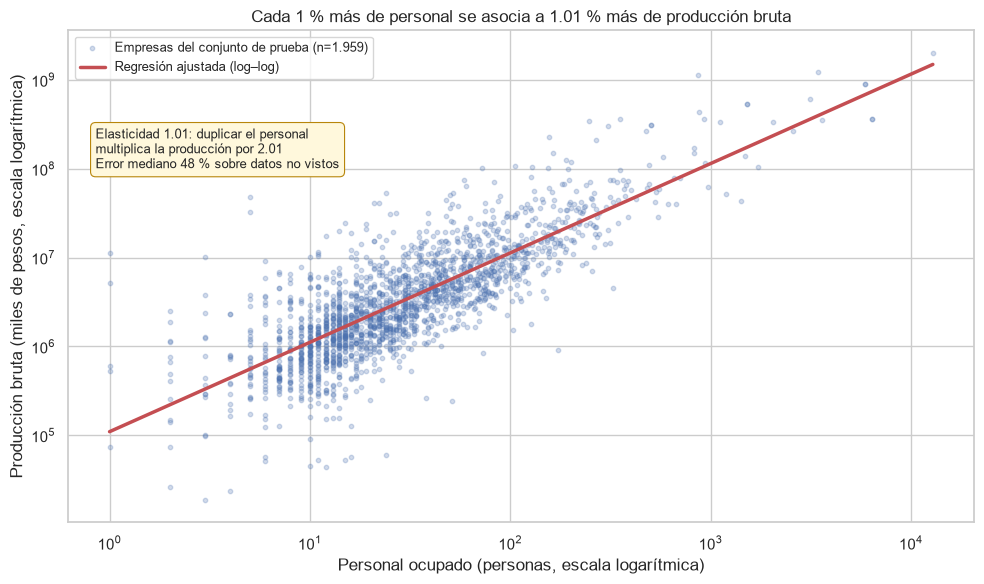

In [13]:
# 5.1 — Dispersión con la recta ajustada  (figura 3.1.4 del cuaderno principal)
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(X_te["personal_total"], y_te, s=10, alpha=0.25, color="#4C72B0",
           label=f"Empresas del conjunto de prueba (n={len(X_te):,})".replace(",", "."))

rejilla = pd.DataFrame({"personal_total": np.linspace(
    np.log(X_te["personal_total"].min()), np.log(X_te["personal_total"].max()), 100)})
ax.plot(np.exp(rejilla["personal_total"]), np.exp(simple.predict(rejilla)),
        color="#C44E52", lw=2.5, label="Regresión ajustada (log–log)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Personal ocupado (personas, escala logarítmica)")
ax.set_ylabel("Producción bruta (miles de pesos, escala logarítmica)")
ax.set_title(f"Cada 1 % más de personal se asocia a {b:.2f} % más de producción bruta")
ax.legend(fontsize=9, loc="upper left")

ax.annotate(f"Elasticidad {b:.2f}: duplicar el personal\n"
            f"multiplica la producción por {2 ** b:.2f}\n"
            f"Error mediano {resultados[0]['error mediano %']:.0f} % sobre datos no vistos",
            xy=(0.03, 0.72), xycoords="axes fraction", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="#FFF8DC", ec="#B8860B", lw=0.8))

plt.tight_layout()
plt.show()


### 5.2 Predicho frente a observado

El modelo múltiple contra la realidad. La diagonal punteada es la predicción perfecta: cuanto más
cerca de ella están los puntos, mejor.

A diferencia de 5.1, este gráfico funciona con cualquier número de predictores, y por eso es el
estándar para presentar un modelo de regresión.

> **Resultado:** la nube se agrupa alrededor de la diagonal sin sesgo visible hacia arriba o
> hacia abajo: el modelo no sobreestima ni subestima de forma sistemática.


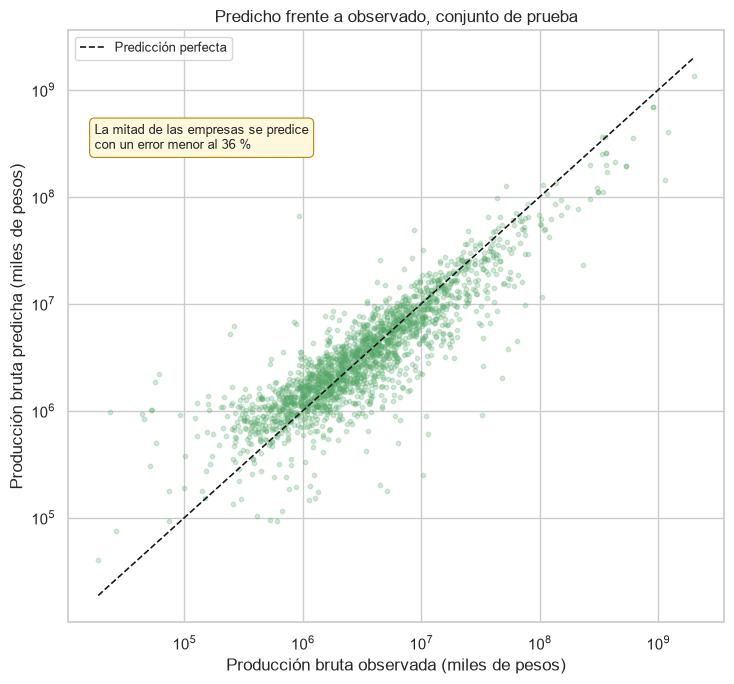

In [14]:
# 5.2 — Predicho frente a observado
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(y_te, pred_multiple, s=10, alpha=0.25, color="#55A868")

lims = [min(y_te.min(), pred_multiple.min()), max(y_te.max(), pred_multiple.max())]
ax.plot(lims, lims, "k--", lw=1.2, label="Predicción perfecta")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Producción bruta observada (miles de pesos)")
ax.set_ylabel("Producción bruta predicha (miles de pesos)")
ax.set_title("Predicho frente a observado, conjunto de prueba")
ax.legend(fontsize=9, loc="upper left")

err_med = resultados[1]["error mediano %"]
ax.annotate(f"La mitad de las empresas se predice\ncon un error menor al {err_med:.0f} %",
            xy=(0.04, 0.80), xycoords="axes fraction", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="#FFF8DC", ec="#B8860B", lw=0.8))

plt.tight_layout()
plt.show()


### 5.3 Diagnóstico de los residuos

El residuo es lo que el modelo no logró explicar. Si al graficarlos apareciera un embudo o una
curva, significaría que la forma del modelo está mal elegida.

> **Resultado:** residuos centrados en cero (media −0,009) y casi simétricos (asimetría 0,04),
> sin patrón visible. El logaritmo convirtió una variable con asimetría +19 en errores
> prácticamente normales: es la confirmación de que la escala elegida en 3.1 era la correcta.


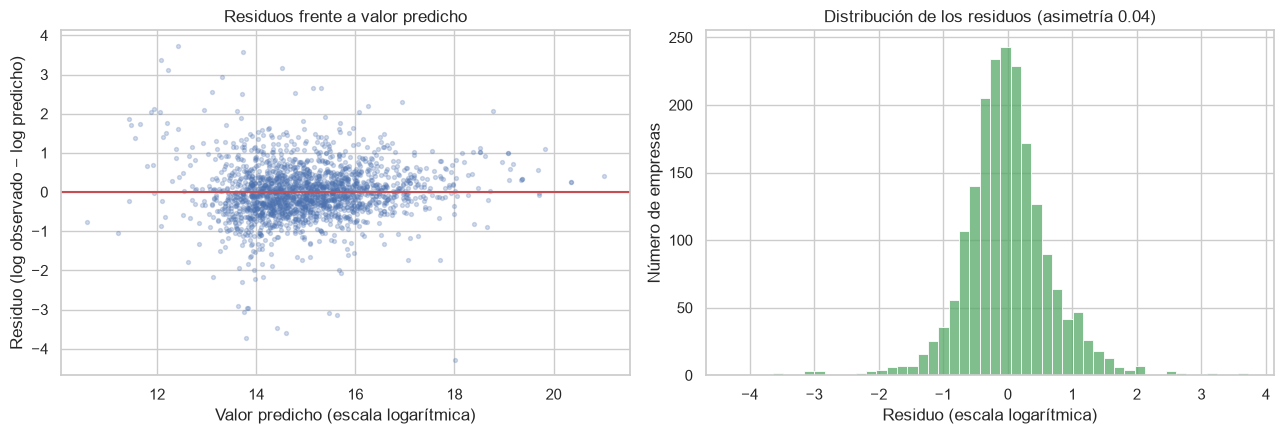

Media de los residuos: -0.0086  |  Asimetría: 0.04


In [15]:
# 5.3 — Diagnóstico de los residuos
resid = np.log(y_te) - multiple.predict(np.log(X_te))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(multiple.predict(np.log(X_te)), resid, s=8, alpha=0.25, color="#4C72B0")
axes[0].axhline(0, color="#C44E52", lw=1.5)
axes[0].set_xlabel("Valor predicho (escala logarítmica)")
axes[0].set_ylabel("Residuo (log observado − log predicho)")
axes[0].set_title("Residuos frente a valor predicho")

sns.histplot(resid, bins=50, ax=axes[1], color="#55A868")
axes[1].set_xlabel("Residuo (escala logarítmica)")
axes[1].set_ylabel("Número de empresas")
axes[1].set_title(f"Distribución de los residuos (asimetría {pd.Series(resid).skew():.2f})")

plt.tight_layout()
plt.show()
print(f"Media de los residuos: {resid.mean():.4f}  |  Asimetría: {pd.Series(resid).skew():.2f}")


## 6. Interpretación

### 6.1 Qué dice el modelo

**Qué hace.** Estima la producción bruta anual de una empresa comercial a partir de dos datos:
cuántas personas emplea y cuánto les paga en total al año.

**Cómo funciona.** Es una regresión lineal ajustada sobre los logaritmos de las tres variables.
Trabajar en logaritmos no es un tecnicismo: en un sector donde la empresa mayor vende 400.000
veces más que la mediana, una recta en escala original queda definida por un puñado de gigantes.
Los coeficientes se leen como elasticidades.

**Qué resultados dio.** Sobre 1.959 empresas que el modelo no vio al entrenar:

| Métrica | Valor |
|---|---|
| R² | 0,729 |
| MAE | 6.280.775 miles de pesos |
| RMSE | 39.390.006 miles de pesos |
| **Error relativo mediano** | **35,5 %** |

La mitad de las empresas se estima con menos de un 35,5 % de error.

**Lo que aprendí de las métricas, que vale más que las métricas.** El modelo sin logaritmos
obtiene un R² *mejor* (0,808) y un error mediano casi el doble de malo (62,8 %). Repitiendo el
experimento con diez particiones distintas, el R² oscila entre 0,65 y 0,92 mientras el error
mediano se mueve menos de dos puntos. En un sector tan concentrado, el R² mide sobre todo lo bien
que se predicen las empresas gigantes. Elegir el modelo por R² habría llevado al peor de los dos.

**Las dos elasticidades.** Personal 0,16, remuneración 0,81: cuánto paga una empresa dice mucho
más sobre su tamaño que a cuánta gente emplea. Es consistente con el hallazgo de 2.5.2 del
cuaderno principal.


### 6.2 Aplicación profesional

**La decisión concreta que habilita.** El personal ocupado y la nómina de una empresa son datos
que una entidad financiera, un gremio o una secretaría de desarrollo económico **ya observan**
—a través de la planilla de seguridad social— sin necesidad de que la empresa entregue sus
estados financieros. Con esos dos datos, este modelo estima su producción bruta anual con un
error mediano del 35 %.

**Para qué sirve eso en la práctica:**

- **Dimensionar un cliente antes de pedirle balances.** Un analista comercial puede priorizar su
  cartera de prospectos por tamaño estimado sin un proceso de solicitud de información.
- **Estimar el tamaño de un segmento entre publicaciones del DANE.** La EAC sale una vez al año;
  la información de nómina es mensual. El modelo permite actualizar una estimación de escala sin
  esperar al siguiente ciclo anual.
- **Detectar inconsistencias.** Una empresa cuya producción declarada se aleje mucho de la
  estimada es candidata a revisión — no porque el modelo tenga razón, sino porque la discrepancia
  es una señal barata de dónde mirar.

**Para qué NO sirve, que es igual de importante decirlo.** Con un error mediano del 35 %, este
modelo **no sirve para decidir un crédito individual** ni para fijar el valor de una empresa. Un
error de un tercio sobre una cifra de miles de millones es mucho dinero. Sirve para **segmentar y
priorizar**, que es una decisión reversible y de bajo costo, no para decidir sobre un caso
concreto.

**Y una limitación honesta:** el modelo se entrenó excluyendo 118 empresas sin personal
remunerado, así que no aplica a empresas familiares sin nómina — justamente un segmento donde la
información externa escasea y el modelo sería más útil.

**Lo que me llevo como método.** Que una métrica alta no valida un modelo: el R² de 1,000 de
la celda 1.3 era perfecto y completamente inútil. Antes de celebrar un resultado hay que
preguntarse si el modelo pudo haber aprendido la respuesta por una vía que no sea la que
pretendía.
